# Eksploracja danych · Laboratorium 7
## Drzewa decyzyjne: kto odejdzie z programu lojalnościowego?

**Sytuacja.** Dział marketingu ma budżet na kupony „wracamy do Ciebie” po 30 zł. Chce je wysłać tylko tym klientom, którzy prawdopodobnie odejdą. Mamy historię: tych samych 1206 klientów co w laboratorium 3 (stan na 30.09.2026) oraz informację, kto **odszedł**, czyli nie złożył żadnego zamówienia od 01.10.2026 do 31.03.2027.

Dziś uczymy **drzewo decyzyjne**: ciąg pytań typu „czy dni od ostatniego zamówienia > 175?”, który kończy się odpowiedzią „odejdzie / zostanie”. Drzewo da się przeczytać i wytłumaczyć szefowi.

**Dane:** `klienci_odejscia.csv` (separator `;`, przecinek dziesiętny).

| Kolumna | Opis |
|---|---|
| `nr_karty`, `region` | numer karty, województwo |
| `liczba_zamowien`, `wydatki_zl`, `sredni_koszyk_zl` | 12 miesięcy do 30.09.2026 |
| `dni_od_ostatniego` | dni od ostatniego zamówienia do 30.09.2026 |
| `udzial_promocji`, `udzial_internet` | udział zamówień z kodem rabatowym / przez internet (0–1) |
| `liczba_kategorii`, `zwroty` | liczba kategorii produktów (1–5), liczba zwrotów |
| `dni_od_logowania_31_03_2027` | dni od ostatniego logowania do konta, liczone **31.03.2027** |
| `odszedl` | **1** = brak zamówienia od 01.10.2026 do 31.03.2027, **0** = kupował dalej |

**Zasada pracy:** luki `___` z komentarzem `UZUPEŁNIJ`. Każdą decyzję zapisujemy w komórce tekstowej. Przed oddaniem: *Kernel → Restart Kernel and Run All Cells*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

import sklearn
print("scikit-learn", sklearn.__version__)
pd.set_option("display.precision", 3)

scikit-learn 1.8.0


## Z1. Rozgrzewka: który podział jest lepszy? Indeks Giniego na kartce

Drzewo wybiera pytanie, po którym grupy są najbardziej **jednorodne** (w każdej prawie same 0 albo same 1). Miarą niejednorodności jest **indeks Giniego**:

$$G = 1 - p_0^2 - p_1^2,$$

gdzie $p_1$ to udział odchodzących w grupie. Grupa jednorodna: G = 0; pół na pół: G = 0,5.
Jakość podziału to **średnia ważona** G obu grup (wagi = udziały klientów).

Na kartce policz dla 10 klientów: G całej grupy, G po podziale „dni_od_ostatniego > 180” i po podziale „liczba_zamowien ≤ 2”. Który podział wybierze drzewo? Potem sprawdź kodem.

In [2]:
t = pd.read_csv("dziesieciu_klientow.csv", sep=";")
t

,klient,dni_od_ostatniego,liczba_zamowien,odszedl
0,A,20,8,0
1,B,45,1,1
2,C,200,2,1
3,D,250,5,1
4,E,60,2,0
5,F,210,1,1
6,G,30,12,0
7,H,190,3,0
8,I,100,1,1
9,J,15,6,0


In [3]:
def gini(y):
    p1 = y.mean()                  # udział odchodzących
    return 1 - p1**2 - (1 - p1)**2   # UZUPEŁNIJ: potęga

def gini_podzialu(warunek, y):
    lewa, prawa = y[warunek], y[~warunek]
    return len(lewa) / len(y) * gini(lewa) + len(prawa) / len(y) * gini(prawa)

y10 = t["odszedl"]
print("G całej grupy:              ", round(gini(y10), 3))
print("podział dni > 180:          ", round(gini_podzialu(t["dni_od_ostatniego"] > 180, y10), 3))
print("podział liczba_zamowien <= 2:", round(gini_podzialu(t["liczba_zamowien"] <= 2, y10), 3))

G całej grupy:               0.5
podział dni > 180:           0.417
podział liczba_zamowien <= 2: 0.32


**Pytanie:** który podział wybierze drzewo i dlaczego? Czy wynik zgadza się z Twoim liczeniem na kartce?

**Odpowiedź:** Lepszy jest podział według liczby zamówień ≤ 2, bo ma niższy indeks Giniego (0,32 zamiast 0,417). Wynik zgadza się z obliczeniami.

## Z2. Dane i punkt odniesienia

Wczytaj dane. Jaki procent klientów odszedł? Jaką **trafność** (odsetek poprawnych odpowiedzi) miałby „model”, który zawsze mówi „zostanie”? To nasz punkt odniesienia: model, który go nie pobije, jest bezużyteczny.

In [4]:
df = pd.read_csv("klienci_odejscia.csv", sep=";", decimal=",")
print(df.shape)
df.head()

(1206, 12)


,nr_karty,region,liczba_zamowien,wydatki_zl,sredni_koszyk_zl,dni_od_ostatniego,udzial_promocji,udzial_internet,liczba_kategorii,zwroty,dni_od_logowania_31_03_2027,odszedl
0,100760,inne,5,5497.00,1099.40,61,0.29,0.62,1,1,9,0
1,100529,mazowieckie,3,612.20,204.07,83,0.64,0.53,1,0,130,1
2,101028,inne,1,275.86,275.86,214,0.17,0.25,1,0,120,1
3,100197,mazowieckie,19,4325.37,227.65,32,0.28,0.87,2,0,1,0
4,100036,wielkopolskie,5,511.66,102.33,270,0.32,0.21,2,0,241,1


In [5]:
print("odeszło:", df["odszedl"].sum(), "z", len(df), f"= {100 * df['odszedl'].mean():.1f}%")
print(f"trafność modelu 'nikt nie odchodzi': {100 * (1 - df['odszedl'].mean()):.1f}%")

odeszło: 381 z 1206 = 31.6%
trafność modelu 'nikt nie odchodzi': 68.4%


In [6]:
# czy odchodzenie zależy od regionu?
df.groupby("region")["odszedl"].agg(["mean", "count"]).sort_values("mean")

,mean,count
region,,
małopolskie,0.270,141
pomorskie,0.303,122
mazowieckie,0.309,298
wielkopolskie,0.327,156
śląskie,0.332,190
inne,0.334,299


**Zapisz:** ile procent odchodzi, jaka jest trafność „nikt nie odchodzi”, czy region różnicuje odchodzenie?

**Odpowiedź:** Odeszło 31,6% klientów, a model „nikt nie odchodzi” ma trafność 68,4%. Różnice między regionami są niewielkie, więc region nie ma większego znaczenia.

## Z3. Pierwsze drzewo: dwa pytania

Kolumny do modelu: wszystkie liczbowe opisujące klienta **do 30.09.2026**. Pomijamy `nr_karty` (identyfikator), `region` (tekst, a w Z2 nie różnicuje), etykietę `odszedl` i na razie kolumnę z logowaniem (wrócimy do niej w Z9).

Uwaga: w k-means (lab. 3) cechy trzeba było **standaryzować**, bo liczyliśmy odległości. Drzewo porównuje każdą kolumnę z progiem osobno, więc skala nie ma znaczenia.

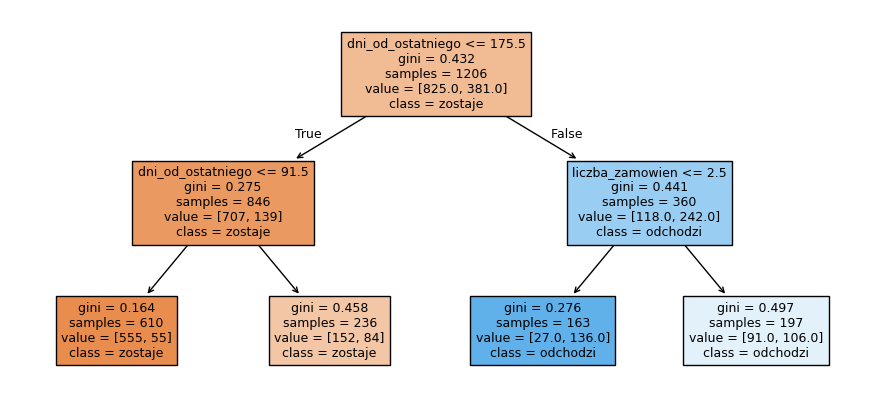

In [7]:
CECHY = ["liczba_zamowien", "wydatki_zl", "sredni_koszyk_zl", "dni_od_ostatniego",
         "udzial_promocji", "udzial_internet", "liczba_kategorii", "zwroty"]
X = df[CECHY]
y = df["odszedl"]                          # UZUPEŁNIJ: kolumna, którą przewidujemy

drzewo2 = DecisionTreeClassifier(max_depth=2, random_state=0)
drzewo2.fit(X, y)

plt.figure(figsize=(11, 5))
plot_tree(drzewo2, feature_names=CECHY, class_names=["zostaje", "odchodzi"], filled=True, impurity=True, proportion=False, fontsize=9)
plt.show()

In [8]:
print(export_text(drzewo2, feature_names=CECHY, show_weights=True))

|--- dni_od_ostatniego <= 175.50
|   |--- dni_od_ostatniego <= 91.50
|   |   |--- weights: [555.00, 55.00] class: 0
|   |--- dni_od_ostatniego >  91.50
|   |   |--- weights: [152.00, 84.00] class: 0
|--- dni_od_ostatniego >  175.50
|   |--- liczba_zamowien <= 2.50
|   |   |--- weights: [27.00, 136.00] class: 1
|   |--- liczba_zamowien >  2.50
|   |   |--- weights: [91.00, 106.00] class: 1



**Jak czytać prostokąt:** pytanie (np. `dni_od_ostatniego <= 175.5`), `gini`, `samples` (ilu klientów), `value` = [ilu zostaje, ilu odchodzi], `class` = odpowiedź większości. W lewo idą klienci, dla których odpowiedź brzmi **tak**.

**Pytanie:** opisz słowami najbardziej „ryzykowny” liść: jakie warunki, ilu klientów, jaki odsetek odchodzi?

**Odpowiedź:** Największe ryzyko mają klienci, którzy nie zamawiali od ponad 175 dni i mają najwyżej 2 zamówienia. W tej grupie jest 163 klientów, z czego 136 odeszło (83,4%).

## Z4. Uczciwy sprawdzian: zbiór uczący i testowy

Model oceniony na danych, na których się uczył, zawsze wypada za dobrze. Odkładamy 30% klientów jako **zbiór testowy**: model ich nie widzi, dopóki nie skończymy wybierać ustawień. `stratify=y` pilnuje, żeby odsetek odchodzących był taki sam w obu częściach.

In [9]:
X_ucz, X_test, y_ucz, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)   # UZUPEŁNIJ: 30% na test
print("uczący:", X_ucz.shape[0], f"odchodzi {100 * y_ucz.mean():.1f}%")
print("testowy:", X_test.shape[0], f"odchodzi {100 * y_test.mean():.1f}%")

uczący: 844 odchodzi 31.6%
testowy: 362 odchodzi 31.5%


## Z5. Przeuczenie: drzewo, które „wie wszystko”

Drzewo bez ograniczenia głębokości dzieli dane tak długo, aż każdy liść jest jednorodny. Na zbiorze uczącym ma wtedy 100% trafności. A na testowym?

In [10]:
pelne = DecisionTreeClassifier(random_state=0).fit(X_ucz, y_ucz)
print("głębokość:", pelne.get_depth(), " liści:", pelne.get_n_leaves())
print(f"trafność, zbiór uczący:  {100 * pelne.score(X_ucz, y_ucz):.1f}%")
print(f"trafność, zbiór testowy: {100 * pelne.score(X_test, y_test):.1f}%")

głębokość: 23  liści: 161
trafność, zbiór uczący:  100.0%


trafność, zbiór testowy: 70.7%


Głębokość wybieramy **bez** zbioru testowego: **walidacją krzyżową**. Zbiór uczący dzielimy na 5 części; model uczymy na 4, sprawdzamy na piątej, i tak 5 razy. Średnia z 5 sprawdzianów mówi, jak model radzi sobie z klientami, których nie widział.

In [11]:
wyniki = []
for g in [1, 2, 3, 4, 5, 6, 8, 10, None]:
    m = DecisionTreeClassifier(max_depth=g, random_state=0)
    walid = cross_val_score(m, X_ucz, y_ucz, cv=5).mean()        # UZUPEŁNIJ: 5 części
    m.fit(X_ucz, y_ucz)
    wyniki.append({"glebokosc": "bez limitu" if g is None else g, "liscie": m.get_n_leaves(),
                   "trafnosc_uczacy": m.score(X_ucz, y_ucz), "trafnosc_walidacja": walid})
wyniki = pd.DataFrame(wyniki)
wyniki

,glebokosc,liscie,trafnosc_uczacy,trafnosc_walidacja
0,1,2,0.793,0.755
1,2,4,0.793,0.774
2,3,8,0.802,0.777
3,4,15,0.825,0.764
4,5,26,0.846,0.767
5,6,39,0.864,0.762
6,8,78,0.916,0.756
7,10,111,0.951,0.738
8,bez limitu,161,1.000,0.713


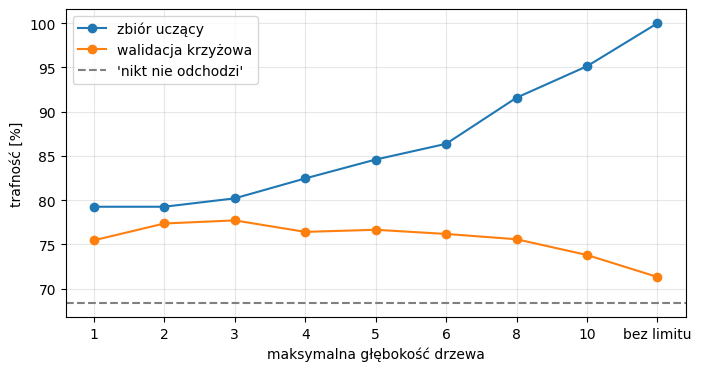

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(wyniki.index, 100 * wyniki["trafnosc_uczacy"], "o-", label="zbiór uczący")
plt.plot(wyniki.index, 100 * wyniki["trafnosc_walidacja"], "o-", label="walidacja krzyżowa")
plt.axhline(100 * (1 - y_ucz.mean()), ls="--", c="grey", label="'nikt nie odchodzi'")
plt.xticks(wyniki.index, wyniki["glebokosc"])
plt.xlabel("maksymalna głębokość drzewa"); plt.ylabel("trafność [%]"); plt.legend(); plt.grid(alpha=.3)
plt.show()

**Pytanie:** przy jakiej głębokości trafność walidacyjna jest najwyższa? Co się dzieje z trafnością na zbiorze uczącym i walidacyjnym, gdy drzewo rośnie dalej? Jak nazywamy to zjawisko?

**Odpowiedź:** Najlepsza głębokość to 3 (77,7% w walidacji). Później trafność treningowa rośnie, a walidacyjna spada. To przeuczenie modelu.

## Z6. Model końcowy i liść z kilkoma klientami

Wybieramy głębokość 3. Dodatkowo wymagamy, żeby każdy liść miał co najmniej 20 klientów (`min_samples_leaf=20`): reguła oparta na 3 klientach nie jest regułą, tylko anegdotą.

In [13]:
bez_min = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_ucz, y_ucz)
liscie = pd.Series(bez_min.apply(X_ucz)).value_counts().sort_values()
print("najmniejsze liście (klientów):", liscie.head(3).tolist())
print(export_text(bez_min, feature_names=CECHY, max_depth=3)[:400])

najmniejsze liście (klientów): [1, 17, 19]
|--- dni_od_ostatniego <= 175.50
|   |--- dni_od_ostatniego <= 92.50
|   |   |--- wydatki_zl <= 83274.50
|   |   |   |--- class: 0
|   |   |--- wydatki_zl >  83274.50
|   |   |   |--- class: 1
|   |--- dni_od_ostatniego >  92.50
|   |   |--- liczba_zamowien <= 2.50
|   |   |   |--- class: 0
|   |   |--- liczba_zamowien >  2.50
|   |   |   |--- class: 0
|--- dni_od_ostatniego >  175.50
|   |--- lic


walidacja krzyżowa: 77.7%
zbiór testowy:      78.2%


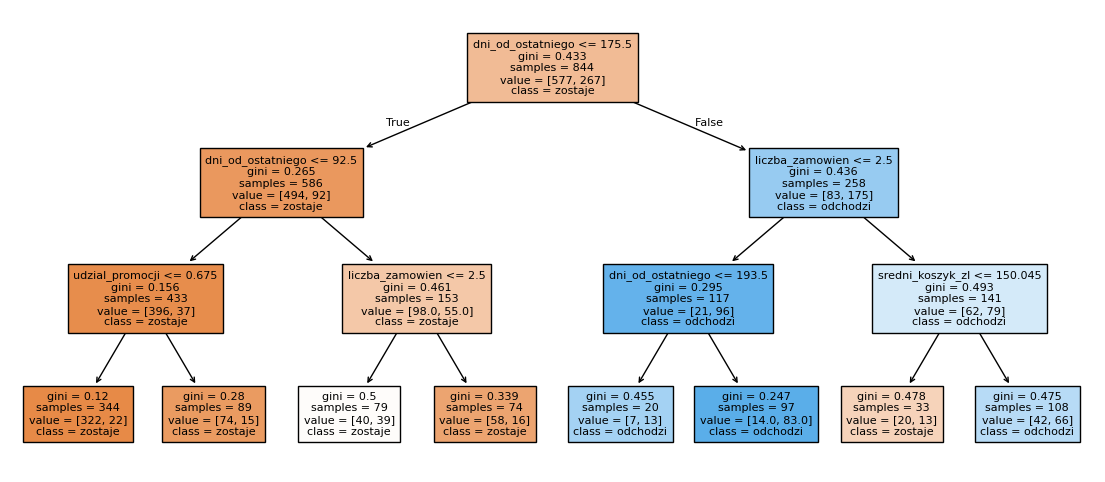

In [14]:
model = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=0).fit(X_ucz, y_ucz)   # UZUPEŁNIJ: min. 20 klientów w liściu
print(f"walidacja krzyżowa: {100 * cross_val_score(model, X_ucz, y_ucz, cv=5).mean():.1f}%")
print(f"zbiór testowy:      {100 * model.score(X_test, y_test):.1f}%")
plt.figure(figsize=(14, 6))
plot_tree(model, feature_names=CECHY, class_names=["zostaje", "odchodzi"], filled=True, fontsize=8)
plt.show()

In [15]:
waznosc = pd.Series(model.feature_importances_, index=CECHY).sort_values(ascending=False)
waznosc.round(3)

dni_od_ostatniego    0.862
liczba_zamowien      0.108
sredni_koszyk_zl     0.018
udzial_promocji      0.012
wydatki_zl           0.000
udzial_internet      0.000
liczba_kategorii     0.000
zwroty               0.000
dtype: float64

**Pytanie:** kim są klienci w najmniejszym liściu drzewa bez `min_samples_leaf` (spójrz na próg `wydatki_zl`)? Skąd ich znamy z laboratorium 3? Które cechy model uznał za najważniejsze?

**Odpowiedź:** W najmniejszym liściu jest jeden klient firmowy z wydatkami 92 206 zł i 56 zamówieniami. To obserwacja odstająca z lab. 3. Najważniejsze cechy to dni od ostatniego zamówienia (0,862) i liczba zamówień (0,108).

## Z7. Macierz pomyłek: trafność to nie wszystko

Trafność łączy dwa różne błędy: **przeoczony** odchodzący klient (nie dostanie kuponu, odejdzie) i **fałszywy alarm** (kupon dla kogoś, kto i tak by został). Rozpisujemy je w macierzy pomyłek na zbiorze testowym.

In [16]:
pred = model.predict(X_test)
cm = confusion_matrix(y_test, pred)        # UZUPEŁNIJ: przewidywania modelu
print(pd.DataFrame(cm, index=["naprawdę zostaje", "naprawdę odchodzi"], columns=["model: zostaje", "model: odchodzi"]))
print()
print(f"trafność:  {100 * accuracy_score(y_test, pred):.1f}%")
print(f"precyzja:  {100 * precision_score(y_test, pred):.1f}%   (z klientów wskazanych przez model, ilu naprawdę odeszło)")
print(f"czułość:   {100 * recall_score(y_test, pred):.1f}%   (z klientów, którzy odeszli, ilu model wskazał)")

                   model: zostaje  model: odchodzi
naprawdę zostaje              221               27
naprawdę odchodzi              52               62

trafność:  78.2%
precyzja:  69.7%   (z klientów wskazanych przez model, ilu naprawdę odeszło)
czułość:   54.4%   (z klientów, którzy odeszli, ilu model wskazał)


**Pytanie:** ilu odchodzących klientów model przeoczył? Ile kuponów trafiłoby do osób, które i tak by zostały? Który błąd jest dla marketingu droższy?

**Odpowiedź:** Model przeoczył 52 odchodzących klientów i wskazał błędnie 27 klientów, którzy zostają. Przeoczenie może być droższe, bo oznacza utraconą marżę 250 zł, ale zależy to od skuteczności kuponu. Fałszywy alarm kosztuje 30 zł.

## Z8. Próg i pieniądze: komu wysłać kupon?

Liść drzewa daje nie tylko odpowiedź, ale też **ryzyko**: odsetek odchodzących w tym liściu (`predict_proba`). Domyślnie kupon dostaje każdy z ryzykiem ≥ 0,5. Ale próg to decyzja biznesowa.

Założenia marketingu: kupon kosztuje **30 zł**; klient, który miał odejść i dostał kupon, zostaje z prawdopodobieństwem **30%**; zatrzymany klient to **250 zł** marży w kolejnym półroczu.
Zysk z kuponu dla klienta z ryzykiem p: p × 0,30 × 250 − 30. Opłaca się, gdy p > 30 / 75 = **0,4**.

In [17]:
KUPON, SKUTECZNOSC, MARZA = 30, 0.30, 250
ryzyko = model.predict_proba(X_test)[:, 1]      # UZUPEŁNIJ: kolumna klasy 'odchodzi'

tabela = []
for prog in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    wyslij = ryzyko >= prog
    zatrzymani = SKUTECZNOSC * y_test[wyslij].sum()
    tabela.append({"prog": prog, "kuponow": int(wyslij.sum()), "trafione_w_odchodzacych": int(y_test[wyslij].sum()),
                   "zysk_zl": round(zatrzymani * MARZA - KUPON * wyslij.sum())})
pd.DataFrame(tabela)

,prog,kuponow,trafione_w_odchodzacych,zysk_zl
0,0.2,183,95,1635
1,0.3,138,82,2010
2,0.4,125,77,2025
3,0.5,89,62,1980
4,0.6,89,62,1980
5,0.7,41,35,1395


In [18]:
# D2: skuteczność kuponu 15% i dodatkowe progi 0,8 oraz 0,9
skutecznosc_d2 = 0.15
wyniki_d2 = []
for prog_d2 in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    wyslij_d2 = ryzyko >= prog_d2
    ile = int(wyslij_d2.sum())
    odchodzacy = int(y_test[wyslij_d2].sum())
    zysk_d2 = skutecznosc_d2 * odchodzacy * MARZA - KUPON * ile
    wyniki_d2.append({"prog": prog_d2, "kuponow": ile, "zysk_zl": zysk_d2})
pd.DataFrame(wyniki_d2)

,prog,kuponow,zysk_zl
0,0.2,183,-1927.5
1,0.3,138,-1065.0
2,0.4,125,-862.5
3,0.5,89,-345.0
4,0.6,89,-345.0
5,0.7,41,82.5
6,0.8,41,82.5
7,0.9,0,0.0


In [19]:
# dla porównania: kupon dla wszystkich klientów ze zbioru testowego
print("kupon dla wszystkich, zysk [zł]:", round(SKUTECZNOSC * y_test.sum() * MARZA - KUPON * len(y_test)))

kupon dla wszystkich, zysk [zł]: -2310


**Pytanie:** przy którym progu zysk jest największy? Dlaczego nie przy 0,5? Ile zarabiamy względem wysłania kuponu wszystkim?

**Odpowiedź:** Największy zysk jest przy progu 0,4: 2025 zł i 125 kuponów. Próg 0,5 daje 1980 zł, bo pomija część klientów, których warto zatrzymać. Wysyłka wszystkim przyniosłaby stratę 2310 zł, więc różnica to 4335 zł.

## Z9. Pułapka: kolumna z przyszłości

Kolega z działu IT proponuje dodać kolumnę `dni_od_logowania_31_03_2027`, bo „poprawia model”. Sprawdź.

In [20]:
CECHY_IT = CECHY + ["dni_od_logowania_31_03_2027"]
Xa, Xb, ya, yb = train_test_split(df[CECHY_IT], y, test_size=0.3, stratify=y, random_state=42)
model_it = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=0).fit(Xa, ya)
print(f"trafność na zbiorze testowym: {100 * model_it.score(Xb, yb):.1f}%")
print(pd.Series(model_it.feature_importances_, index=CECHY_IT).sort_values(ascending=False).round(3).head(3))

trafność na zbiorze testowym: 99.4%
dni_od_logowania_31_03_2027    1.0
liczba_zamowien                0.0
wydatki_zl                     0.0
dtype: float64


**Pytanie:** dlaczego model z tą kolumną jest prawie idealny? Czy można go użyć 1 października 2026, kiedy decydujemy o kuponach? Jak nazywa się taki błąd?

**Odpowiedź:** Ta kolumna pochodzi z 31.03.2027, więc pokazuje informacje z przyszłości. Nie można jej użyć przy decyzji z 1.10.2026. To wyciek danych (data leakage).

## Z10. Kalkulator ryzyka w Streamlit (GitHub → Render)

W repozytorium jest plik `app.py`: aplikacja, która uczy to samo drzewo (głębokość 3, min. 20 klientów w liściu) i pokazuje ryzyko odejścia dla klienta wpisanego w formularzu oraz ścieżkę pytań w drzewie.
1. W Codespaces: `pip install -r requirements.txt`, potem `streamlit run app.py`; otwórz port 8501.
2. Wpisz klienta: 1 zamówienie, 200 dni od ostatniego. Jakie ryzyko? Czy dostaje kupon przy progu 0,4?
3. `git add`, `git commit`, `git push`; na Render: *New → Web Service* z Twojego repozytorium (ustawienia są w `render.yaml`).
4. Link do aplikacji wklej do karty zadań.

**Wynik testu:** Dla 1 zamówienia i 200 dni od ostatniego zamówienia ryzyko wynosi ok. 86%. Przy progu 0,4 klient dostaje kupon. Link do Render należy wkleić po publikacji aplikacji.


## Zadanie domowe
**D1.** Narysuj (na kartce albo w Markdown) model końcowy z Z6 jako 3–4 reguły dla działu marketingu: „JEŚLI … I … TO ryzyko …%”.

**D2.** Zmień założenia z Z8: skuteczność kuponu 15% zamiast 30%. Jaki jest próg opłacalności i najlepszy próg w tabeli? Ilu klientów dostaje kupon?

**D3.** W laboratorium 3 podzieliliśmy klientów na segmenty k-means. Dlaczego k-means nie mógł nam powiedzieć, kto odejdzie, a drzewo może? Dwa zdania.

### Odpowiedzi

**D1. Przykładowe reguły końcowego drzewa:**

- JEŚLI dni od ostatniego zamówienia ≤ 92 I udział promocji ≤ 0,68, TO ryzyko odejścia to ok. **6,4%**.
- JEŚLI dni od ostatniego zamówienia > 92 i ≤ 175 I liczba zamówień ≤ 2, TO ryzyko to ok. **49,4%**.
- JEŚLI dni od ostatniego zamówienia > 175 I liczba zamówień ≤ 2 I dni od ostatniego ≤ 193, TO ryzyko to **65,0%**.
- JEŚLI dni od ostatniego zamówienia > 193 I liczba zamówień ≤ 2, TO ryzyko to ok. **85,6%**.

**D2.** Przy skuteczności kuponu 15% próg opłacalności to 30 / (0,15 × 250) = **0,8**. W tabeli najwyższy zysk jest przy progu **0,7 i 0,8**: **41 kuponów** i **82,50 zł** zysku (zaokrąglając do pełnych zł: 82 zł). Próg 0,8 jest sensownym wyborem, bo odpowiada obliczonemu progowi opłacalności.

**D3.** K-means dzielił klientów na podobne grupy, ale nie wiedział, kto odszedł. Drzewo uczy się na kolumnie `odszedl`, dlatego może przewidywać odejście kolejnych klientów.
